# Lecture 4 — Class Exercise
## Scatter & Bubble Charts: Gapminder

> **Push to:** `week04/lecture04_exercise.ipynb`

**Rules:**
1. Colour used **sparingly** — one categorical variable, no rainbow
2. If showing all continents, either use accessible palette OR grey all + highlight one
3. `size_max` set when using bubble size
4. Log scale for GDP per capita
5. Insight title

---


In [2]:
import pandas as pd
import plotly.express as px


# Dataset: Gapminder — GDP, Life Expectancy, Population by Country
# Source: Gapminder Foundation (gapminder.org)

df = px.data.gapminder()
print(f"Loaded: {len(df)} rows")
print(df.head())

Loaded: 1704 rows
       country continent  year  lifeExp       pop   gdpPercap iso_alpha  \
0  Afghanistan      Asia  1952   28.801   8425333  779.445314       AFG   
1  Afghanistan      Asia  1957   30.332   9240934  820.853030       AFG   
2  Afghanistan      Asia  1962   31.997  10267083  853.100710       AFG   
3  Afghanistan      Asia  1967   34.020  11537966  836.197138       AFG   
4  Afghanistan      Asia  1972   36.088  13079460  739.981106       AFG   

   iso_num  
0        4  
1        4  
2        4  
3        4  
4        4  


In [3]:
# explore

print(df.info())
print("Years:", sorted(df['year'].unique()))
print("Continents:", df['continent'].unique())
print(df.describe().round(1))


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1704 entries, 0 to 1703
Data columns (total 8 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   country    1704 non-null   object 
 1   continent  1704 non-null   object 
 2   year       1704 non-null   int64  
 3   lifeExp    1704 non-null   float64
 4   pop        1704 non-null   int64  
 5   gdpPercap  1704 non-null   float64
 6   iso_alpha  1704 non-null   object 
 7   iso_num    1704 non-null   int64  
dtypes: float64(2), int64(3), object(3)
memory usage: 106.6+ KB
None
Years: [np.int64(1952), np.int64(1957), np.int64(1962), np.int64(1967), np.int64(1972), np.int64(1977), np.int64(1982), np.int64(1987), np.int64(1992), np.int64(1997), np.int64(2002), np.int64(2007)]
Continents: ['Asia' 'Europe' 'Africa' 'Americas' 'Oceania']
         year  lifeExp           pop  gdpPercap  iso_num
count  1704.0   1704.0  1.704000e+03     1704.0   1704.0
mean   1979.5     59.5  2.960121e+07     7215.3    

## Task 1 — Scatter: life expectancy change over time

**What to build:** A scatter showing **GDP per capita vs life expectancy** for **two years** (2002 and 2007) to show how both moved — use **colour for year** (just 2 colours), **one continent only**.

Choose any continent except Africa (that was the example). Highlight the change direction.

> 💡 Filter: `df.loc[df['continent'] == 'YOUR_CHOICE']` then filter years


In [3]:
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go

# Step 1: Load the dataset FIRST
df = px.data.gapminder()

# Step 2: Filter Asia and the two years
continent_choice = "Asia"
years = [2002, 2007]

task1_df = df.loc[
    (df["continent"] == continent_choice) &
    (df["year"].isin(years))
].copy()

# Step 3: Create the scatter plot
fig = px.scatter(
    task1_df,
    x="gdpPercap",
    y="lifeExp",
    color="year",
    color_discrete_map={
        2002: "#2878B5",
        2007: "#E07A2D"
    },
    hover_name="country",
    title="GDP per Capita vs Life Expectancy in Asia (2002 vs 2007)",
    labels={
        "gdpPercap": "GDP per capita (US dollars)",
        "lifeExp": "Life expectancy (years)",
        "year": "Year"
    }
)

# Step 4: Add lines showing each country's direction of change
for country, group in task1_df.groupby("country"):
    group = group.sort_values("year")

    if len(group) == 2:
        fig.add_trace(
            go.Scatter(
                x=group["gdpPercap"],
                y=group["lifeExp"],
                mode="lines",
                line=dict(color="grey", width=1),
                opacity=0.5,
                showlegend=False,
                hoverinfo="skip"
            )
        )

fig.update_layout(template="plotly_white")
fig.show()

## Task 2 — Bubble chart: tell a story

**What to build:** A bubble chart (full 2007 dataset, all countries) where:
- x = GDP per capita (log scale)
- y = life expectancy
- size = population
- colour = ONE continent highlighted (your choice), all others grey
- At least one annotation explaining the highlighted group's story

> This is the grey-and-highlight technique applied to a bubble chart.


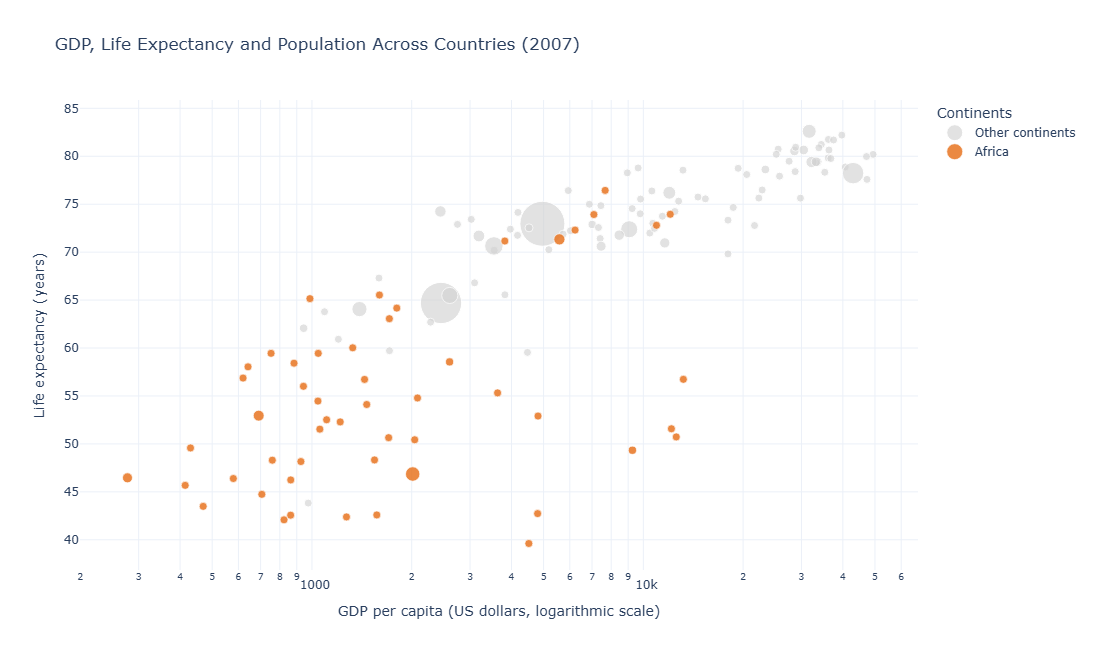

Countries plotted: 142
African countries highlighted: 52
Average life expectancy in Africa: 54.8 years
Average life expectancy elsewhere: 74.1 years


In [5]:
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go

# Step 1: Load the full dataset for 2007
df = px.data.gapminder()
bubble_df = df.loc[df["year"] == 2007].copy()

highlight_continent = "Africa"

# Step 2: Separate Africa from all other continents
other_df = bubble_df[
    bubble_df["continent"] != highlight_continent
]

africa_df = bubble_df[
    bubble_df["continent"] == highlight_continent
]

# Step 3: Create the chart
fig = go.Figure()

# All other continents in grey
fig.add_trace(go.Scatter(
    x=other_df["gdpPercap"],
    y=other_df["lifeExp"],
    mode="markers",
    name="Other continents",
    text=other_df["country"],
    marker=dict(
        size=other_df["pop"],
        sizemode="area",
        sizeref=2.0 * bubble_df["pop"].max() / (45 ** 2),
        sizemin=4,
        color="lightgrey",
        opacity=0.65
    ),
    customdata=other_df[["continent", "pop"]],
    hovertemplate=(
        "<b>%{text}</b><br>"
        "Continent: %{customdata[0]}<br>"
        "GDP per capita: $%{x:,.0f}<br>"
        "Life expectancy: %{y:.1f} years<br>"
        "Population: %{customdata[1]:,.0f}"
        "<extra></extra>"
    )
))

# Africa highlighted in orange
fig.add_trace(go.Scatter(
    x=africa_df["gdpPercap"],
    y=africa_df["lifeExp"],
    mode="markers",
    name="Africa",
    text=africa_df["country"],
    marker=dict(
        size=africa_df["pop"],
        sizemode="area",
        sizeref=2.0 * bubble_df["pop"].max() / (45 ** 2),
        sizemin=4,
        color="#E87522",
        opacity=0.85,
        line=dict(width=0.7, color="white")
    ),
    customdata=africa_df[["continent", "pop"]],
    hovertemplate=(
        "<b>%{text}</b><br>"
        "Continent: %{customdata[0]}<br>"
        "GDP per capita: $%{x:,.0f}<br>"
        "Life expectancy: %{y:.1f} years<br>"
        "Population: %{customdata[1]:,.0f}"
        "<extra></extra>"
    )
))

# Step 4: Add an annotation explaining the pattern
fig.add_annotation(
    x=africa_df["gdpPercap"].median(),
    y=africa_df["lifeExp"].median(),
    text=(
        "Africa: many countries had<br>"
        "lower GDP per capita and<br>"
        "lower life expectancy in 2007"
    ),
    showarrow=True,
    arrowhead=2,
    ax=100,
    ay=-65,
    bgcolor="white",
    bordercolor="#E87522",
    borderwidth=1,
    borderpad=6
)

# Step 5: Configure axes and layout
fig.update_xaxes(
    type="log",
    title="GDP per capita (US dollars, logarithmic scale)"
)

fig.update_yaxes(
    title="Life expectancy (years)"
)

fig.update_layout(
    title="GDP, Life Expectancy and Population Across Countries (2007)",
    template="plotly_white",
    legend_title="Continents",
    height=650
)

fig.show()

# Step 6: Print summary statistics
print("Countries plotted:", len(bubble_df))
print("African countries highlighted:", len(africa_df))

print(
    "Average life expectancy in Africa:",
    round(africa_df["lifeExp"].mean(), 1), "years"
)

print(
    "Average life expectancy elsewhere:",
    round(other_df["lifeExp"].mean(), 1), "years"
)